# 02 平台总览与核心指标

先搞清楚这个平台「平时长什么样」：规模多大、用户多久来一次、GMV 由什么驱动。
这一节的指标和看板「总览」「异常归因」两页是同一套口径（`ads_daily_metrics`）。

指标定义见 [docs/metrics_system.md](../docs/metrics_system.md)。
11-15、11-16 购买埋点缺失（见 notebook 01），涉及购买的指标在图上标灰、计算基线时跳过。

In [1]:
from nbutils import *
import numpy as np

d = q("SELECT * FROM ads_daily_metrics ORDER BY event_date")
d["event_date"] = pd.to_datetime(d.event_date)
CAMPAIGN = pd.date_range("2019-11-15", "2019-11-17")
normal = ~d.event_date.isin(CAMPAIGN)   # 平日：排除大促 3 天（含埋点缺失的两天）

## 1. 规模与使用节律

In [2]:
p = q("SELECT * FROM dws_user_profile")
last = d.iloc[-1]
summary = pd.Series({
    "两个月访问用户": f"{len(p):,}",
    "平日日均 DAU": f"{d[normal].dau.mean():,.0f}",
    "11-30 的 WAU / MAU": f"{last.wau:,.0f} / {last.mau:,.0f}",
    "平日 DAU / WAU（WAU 完整的日子）": pct(d[normal & d.wau_complete].dau_wau_ratio.mean()),
    "11-30 的 DAU / MAU": pct(last.dau / last.mau),
    "两个月内只来过 1 天的用户": pct((p.active_days == 1).mean()),
    "两个月内下过单的用户": pct((p.total_orders > 0).mean()),
})
summary.to_frame("值")

,值
两个月访问用户,"5,315,091"
平日日均 DAU,"236,826"
11-30 的 WAU / MAU,"1,269,466 / 3,695,695"
平日 DAU / WAU（WAU 完整的日子）,20.3%
11-30 的 DAU / MAU,6.9%
两个月内只来过 1 天的用户,50.8%
两个月内下过单的用户,13.1%


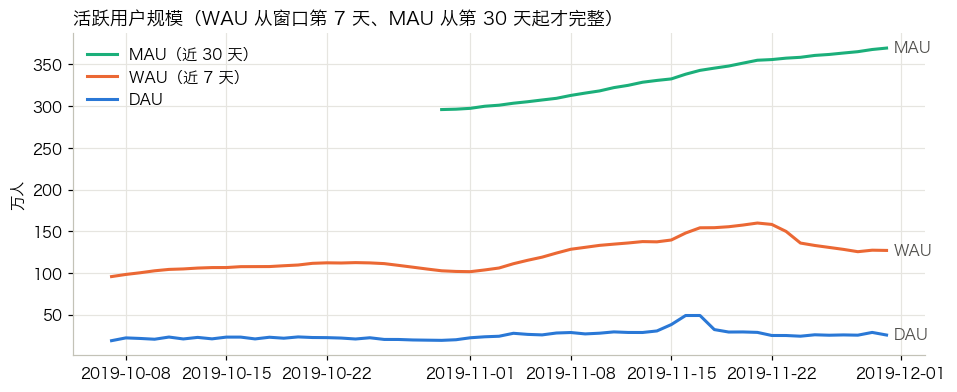

In [3]:
fig, ax = plt.subplots(figsize=(10, 3.8))
v = d[d.wau_complete]
for col, name, c in [("mau", "MAU（近 30 天）", PALETTE[2]), ("wau", "WAU（近 7 天）", PALETTE[1]), ("dau", "DAU", PALETTE[0])]:
    s = d[d.mau_complete] if col == "mau" else v
    ax.plot(s.event_date, s[col] / 1e4, color=c, label=name)
    ax.text(s.event_date.iloc[-1] + pd.Timedelta(days=0.5), s[col].iloc[-1] / 1e4, name.split("（")[0], color="#52514e", va="center")
ax.set(ylabel="万人", title="活跃用户规模（WAU 从窗口第 7 天、MAU 从第 30 天起才完整）")
ax.legend(loc="upper left")
plt.show()

**这是一个周频、而不是日频的平台。** 平日每天来的人只占近 7 天来过的人的 20% 左右，DAU/MAU 只有 7%；
一半用户两个月里只来过 1 天。所以：

- 「流失」不能按「昨天没来」定义——两三天不来是正常节律。生命周期分层（notebook 03）按「沉默多少天」切，第一档就是 7 天；
- 留存要同时看「第 N 天当天回访」和「N 天内回访过」，前者对周频平台会显得很低（notebook 03）。

## 2. GMV 的拆解公式

$$\text{GMV} = \underbrace{\text{DAU}}_{\text{流量}} \times \underbrace{\frac{\text{下单用户}}{\text{DAU}}}_{\text{下单转化率}} \times \underbrace{\frac{\text{订单数}}{\text{下单用户}}}_{\text{人均订单}} \times \underbrace{\frac{\text{GMV}}{\text{订单数}}}_{\text{客单价}}$$

四个因子分别对应流量、转化、复购深度、客单价，各自有不同的负责团队和抓手。GMV 一动，先看是哪个因子在动。

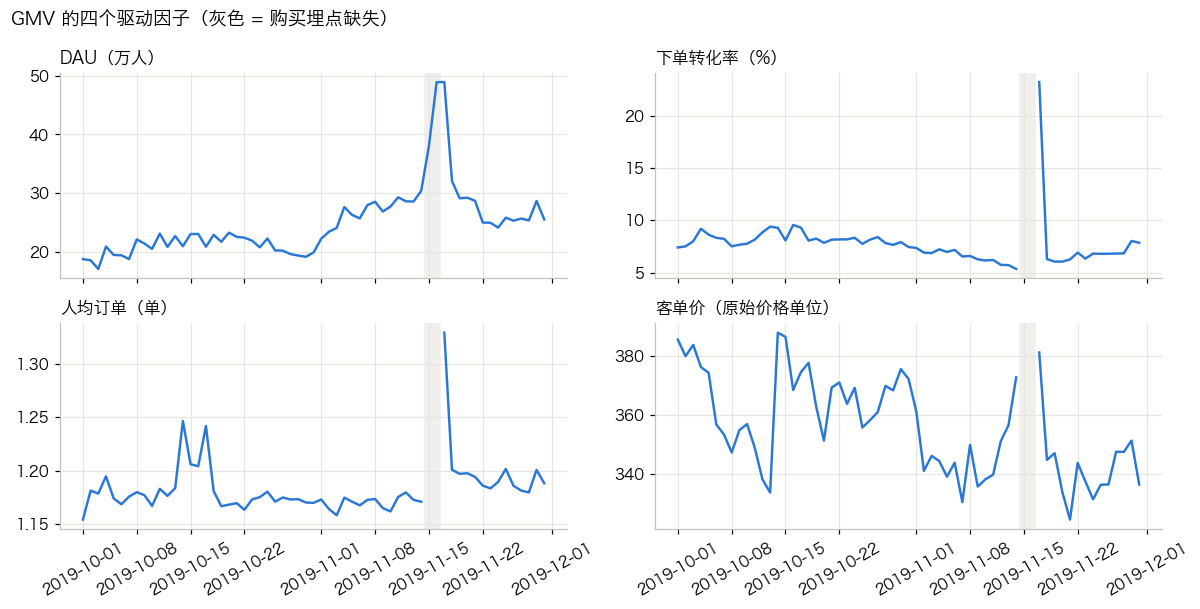

In [4]:
factors = [("dau", "DAU", "万人", 1e4), ("buyer_conversion", "下单转化率", "%", 0.01),
           ("orders_per_buyer", "人均订单", "单", 1), ("aov", "客单价", "原始价格单位", 1)]
fig, axes = plt.subplots(2, 2, figsize=(11, 5.6), sharex=True)
for ax, (col, name, unit, k) in zip(axes.flat, factors):
    s = d.copy()
    if col != "dau":
        s.loc[s.event_date.isin(pd.to_datetime(list(OUTAGE))), col] = np.nan
    shade_outage(ax, label=False)
    ax.plot(s.event_date, s[col] / k, color=PALETTE[0], linewidth=1.6)
    ax.set_title(f"{name}（{unit}）", fontsize=11)
for ax in axes[1]:
    ax.tick_params(axis="x", rotation=30)
fig.suptitle("GMV 的四个驱动因子（灰色 = 购买埋点缺失）", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

## 3. 异常波动归因

**方法**：每天的四个因子各自和「过去 10 天里的平日均值」比（排除大促 3 天），取对数后

$$\ln\frac{\text{GMV}_t}{\text{GMV}_{\text{基线}}} = \ln\frac{\text{DAU}_t}{\text{DAU}_{\text{基线}}} + \ln\frac{\text{转化}_t}{\text{转化}_{\text{基线}}} + \ln\frac{\text{人均订单}_t}{\text{人均订单}_{\text{基线}}} + \ln\frac{\text{客单价}_t}{\text{客单价}_{\text{基线}}}$$

对数让乘法变加法，四项贡献正好加总成 GMV 的变化，不会有「交叉项归谁」的问题。
GMV 偏离基线超过 ±15% 的日子标为异常，并给出贡献最大的因子。看板「异常归因」页用的是同一段逻辑（`pipeline/export_dashboard.py`）。

In [5]:
cols = [c for c, *_ in factors]
names = {c: n for c, n, *_ in factors}
base = {c: d[c].where(normal).shift(1).rolling(10, min_periods=5).mean() for c in cols}
d["gmv_base"] = np.prod([base[c] for c in cols], axis=0)
for c in cols:
    d[f"contrib_{c}"] = np.log(d[c] / base[c])
d["gmv_change"] = d.gmv / d.gmv_base - 1
d["log_change"] = np.log(d.gmv / d.gmv_base)

flag = d[(d.log_change.abs() > np.log(1.15)) & ~d.event_date.isin(pd.to_datetime(list(OUTAGE)))].copy()
flag["主要驱动"] = flag[[f"contrib_{c}" for c in cols]].abs().idxmax(axis=1).str.replace("contrib_", "").map(names)
show = flag[["event_date", "gmv", "gmv_base", "gmv_change"] + [f"contrib_{c}" for c in cols] + ["主要驱动"]]
show.columns = ["日期", "GMV", "基线 GMV", "GMV 变化"] + [f"{names[c]}贡献" for c in cols] + ["主要驱动"]
show.style.format({"日期": "{:%m-%d %a}", "GMV": "{:,.0f}", "基线 GMV": "{:,.0f}", "GMV 变化": "{:+.0%}",
                   **{f"{names[c]}贡献": "{:+.3f}" for c in cols}}).hide(axis="index")

日期,GMV,基线 GMV,GMV 变化,DAU贡献,下单转化率贡献,人均订单贡献,客单价贡献,主要驱动
10-13 Sun,"8,403,372","7,070,462",+19%,+0.109,+0.132,+0.005,-0.073,下单转化率
10-14 Mon,"9,383,242","7,288,505",+29%,+0.001,+0.103,+0.057,+0.091,下单转化率
10-15 Tue,"8,653,941","7,354,087",+18%,+0.096,-0.037,+0.019,+0.084,DAU
10-16 Wed,"9,748,248","7,476,682",+30%,+0.079,+0.138,+0.015,+0.033,下单转化率
10-17 Thu,"9,009,389","7,764,828",+16%,-0.037,+0.096,+0.043,+0.046,下单转化率
10-26 Sat,"6,910,617","8,010,474",-14%,-0.091,-0.025,-0.010,-0.022,DAU
10-29 Tue,"6,391,921","7,397,876",-14%,-0.104,-0.058,+0.002,+0.014,DAU
11-04 Mon,"8,063,078","6,771,385",+19%,+0.272,-0.054,+0.003,-0.047,DAU
11-17 Sun,"57,517,324","7,018,070",+720%,+0.541,+1.341,+0.126,+0.094,下单转化率
11-18 Mon,"8,341,939","7,005,892",+19%,+0.116,+0.047,+0.025,-0.013,DAU


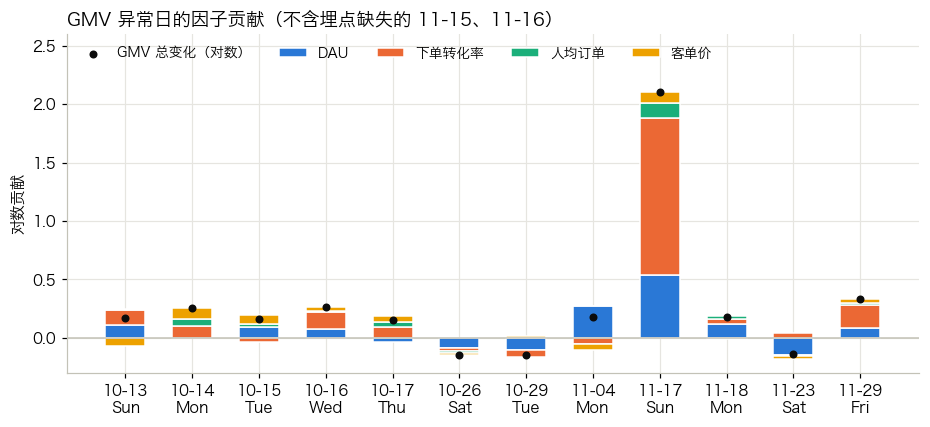

In [6]:
fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(flag))
pos = np.zeros(len(flag)); neg = np.zeros(len(flag))
for c, color in zip(cols, PALETTE):
    vals = flag[f"contrib_{c}"].to_numpy()
    bottom = np.where(vals >= 0, pos, neg)
    ax.bar(x, vals, bottom=bottom, color=color, width=0.6, label=names[c], edgecolor="white", linewidth=1)
    pos += np.where(vals >= 0, vals, 0); neg += np.where(vals < 0, vals, 0)
ax.scatter(x, flag.log_change, color="#0b0b0b", zorder=5, s=18, label="GMV 总变化（对数）")
ax.axhline(0, color="#c3c2b7", linewidth=1)
ax.set_xticks(x, flag.event_date.dt.strftime("%m-%d\n%a"))
ax.set(ylabel="对数贡献", title="GMV 异常日的因子贡献（不含埋点缺失的 11-15、11-16）")
ax.set_ylim(-0.3, 2.6)
ax.legend(ncol=5, loc="upper left", fontsize=9)
plt.show()

**读法**（对数贡献 0.1 ≈ 拉动 GMV 10%）：

- **11-17 大促日**：GMV 是基线的 8 倍多。下单转化率贡献 1.34（约 3.8 倍），DAU 贡献 0.54（多了七成）——
  大促的本质是「来的人转化了」，不只是「来了更多的人」；
- **11-29 黑五**：GMV +39%，主要也是转化（+0.20），流量只贡献 +0.09；
- **10-13 ~ 10-17 连续 5 天**：转化驱动为主，10-14、10-15 还叠加了客单价上升，像是一轮持续一周的高价品类促销；
- **11-04（周一）、11-18（大促次日）**：流量驱动，DAU 跳涨、转化没怎么变。11-04 像一次拉新或推送，11-18 是大促的流量余温；
- **10-26、10-29、11-23**：流量回落导致的 -13% ~ -14%，转化正常，属于正常波动的下沿。

归因只能告诉你「哪个因子在动」，回答不了「为什么动」。要回答后者得有活动日历、渠道来源、推送日志——
这份数据都没有，是埋点需求里要补的东西（`docs/tracking_plan.md`）。

## 4. 一个不在异常列表里、但更值得关注的趋势：大促前的观望期

In [7]:
pre = d[(d.event_date >= "2019-11-01") & (d.event_date <= "2019-11-14")]
first, last7 = pre.head(7), pre.tail(7)
trend = pd.DataFrame({
    "11-01~11-07": [first.dau.mean(), first.buyer_conversion.mean(), first.gmv.mean()],
    "11-08~11-14": [last7.dau.mean(), last7.buyer_conversion.mean(), last7.gmv.mean()],
}, index=["日均 DAU", "下单转化率", "日均 GMV"])
trend["变化"] = trend.iloc[:, 1] / trend.iloc[:, 0] - 1
trend.style.format("{:,.0f}", subset=pd.IndexSlice[["日均 DAU", "日均 GMV"], trend.columns[:2]]) \
    .format("{:.2%}", subset=pd.IndexSlice[["下单转化率"], trend.columns[:2]]).format("{:+.1%}", subset=["变化"])

,11-01~11-07,11-08~11-14,变化
日均 DAU,"253,167","285,587",+12.8%
下单转化率,7.00%,6.00%,-14.3%
日均 GMV,"7,107,691","6,991,443",-1.6%


11 月前两周对比：日均 DAU +13%，下单转化率 -14%，GMV 反而 -2%。流量在涨、转化在跌，一涨一跌刚好抵消——
用户在浏览、比价、等大促。单看 GMV 会把这两周判断成「平稳」，拆开才知道两个因子在往相反方向走。

这对运营的含义：大促前的流量增长不该按平时的转化率去估 GMV；大促前一周压价促单可能只是把大促的单提前了，
而不是新增（大促后有没有透支，见 notebook 06）。

## 5. 周内规律

In [8]:
wk = d[normal].assign(weekday=d.event_date.dt.dayofweek).groupby("weekday")[["dau", "buyer_conversion", "gmv"]].mean()
wk.index = ["周一", "周二", "周三", "周四", "周五", "周六", "周日"]
wk_idx = wk / wk.mean()
wk.assign(**{"DAU 指数": wk_idx.dau, "转化率指数": wk_idx.buyer_conversion, "GMV 指数": wk_idx.gmv}) \
  .style.format({"dau": "{:,.0f}", "buyer_conversion": "{:.2%}", "gmv": "{:,.0f}",
                 "DAU 指数": "{:.2f}", "转化率指数": "{:.2f}", "GMV 指数": "{:.2f}"})

,dau,buyer_conversion,gmv,DAU 指数,转化率指数,GMV 指数
周一,"245,675",7.49%,"7,634,725",1.04,1.00,1.04
周二,"238,734",7.15%,"7,125,237",1.01,0.95,0.97
周三,"236,747",7.39%,"7,282,788",1.00,0.99,1.00
周四,"234,873",7.31%,"7,102,257",0.99,0.98,0.97
周五,"241,829",7.75%,"7,898,902",1.02,1.03,1.08
周六,"228,606",7.65%,"7,055,729",0.97,1.02,0.96
周日,"230,549",7.68%,"7,082,920",0.97,1.03,0.97


周内波动不大（指数都在 0.95–1.08 之间）：周一流量最高，周五 GMV 最高（转化率也最高），周二转化最低。
看日报时要和「上周同一天」比，而不是和昨天比，否则周一的流量高点、周末的流量低点会被误读成异常。